<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/08_oriented_boxes_app_aerial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛰️ Application · Oriented bounding boxes: reading the Earth from above

From space or from a drone, the world is full of **rotated objects**: ships moored diagonally in a harbour, planes
parked at an angle, rows of cars in a car park, storage tanks, bridges. A normal (axis-aligned) box around a diagonal
ship contains mostly water, and in a crowded harbour the boxes of neighbouring ships overlap so much that the detector
gets confused.

**Oriented bounding boxes (OBB)** add one number, the **angle**, so the box hugs the object.

```
 axis-aligned box         oriented box
 ┌───────────┐               ╱╲
 │    ╱╲     │              ╱  ╲
 │   ╱  ╲    │   →         ╱    ╲      (x_center, y_center, width, height, angle)
 │  ╱    ╲   │             ╲    ╱
 └───────────┘              ╲  ╱
```

**DOTA** (*Dataset for Object deTection in Aerial images*, Wuhan University, 2018) made OBB a research field: 2 806
aerial images up to 4 000×4 000 pixels, 15 classes (plane, ship, storage tank, harbour, small/large vehicle,
swimming pool…). Uses range from port and maritime monitoring (illegal fishing), urban planning and traffic analysis
to disaster damage assessment. Kaggle's *Airbus Ship Detection* challenge (2018) was a famous competition on the same
problem.

**Your mission:** understand OBB geometry, use a DOTA-trained YOLO26n-obb, then build an OBB detector **ourselves**
from a regular detector, and measure how much data matters.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import os, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from PIL import Image

os.environ["YOLO_VERBOSE"] = "False"          # quiet logs ("True" to watch every training step)
from ultralytics import YOLO
from ultralytics.utils import YAML
from ultralytics.utils.checks import check_yaml

DEVICE = get_device()
YOLO_DATA = DATA_DIR / "yolo_datasets"
WEIGHTS = DATA_DIR / "weights"
WEIGHTS.mkdir(exist_ok=True)


def yolo_dataset(yaml_name: str) -> Path:
    """Download an Ultralytics dataset into data/yolo_datasets/ and return a YAML pointing to it."""
    cfg = YAML.load(check_yaml(f"{yaml_name}.yaml"))
    folder = YOLO_DATA / Path(cfg["path"]).name
    if not folder.exists():
        url = cfg["download"]
        stem = Path(url).stem
        archive = download(url, YOLO_DATA / Path(url).name)
        tmp = extract(archive, YOLO_DATA / f"_tmp_{stem}")
        inner = tmp / stem if (tmp / stem).is_dir() else tmp
        shutil.move(str(inner), str(folder))
        shutil.rmtree(tmp, ignore_errors=True)
        archive.unlink()
    cfg["path"] = str(folder)
    cfg.pop("download", None)
    out = YOLO_DATA / f"{yaml_name}.yaml"
    YAML.save(out, cfg)
    return out

quest("Read the Earth from above", chapter="Track 3 · Computer vision · Oriented bounding boxes", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Read the Earth from above
   Track 3 · Computer vision · Oriented bounding boxes
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. OBB geometry 📐

An OBB can be written two ways:
- **xywhr**: centre, width, height and rotation angle *r* (in radians), compact and used inside the model;
- **4 corners** `x1 y1 x2 y2 x3 y3 x4 y4`: used in DOTA-style label files (normalised by the image size for YOLO).

Let's convert one to the other and measure how much space an axis-aligned box wastes around a rotated ship.

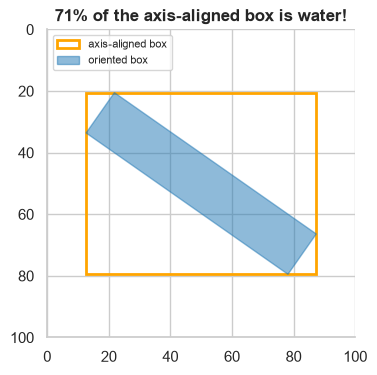

In [3]:
def xywhr_to_corners(xc, yc, w, h, r):
    """Rotate the 4 corners of a w×h rectangle by angle r around its centre."""
    dx, dy = np.array([-w, w, w, -w]) / 2, np.array([-h, -h, h, h]) / 2
    cos, sin = np.cos(r), np.sin(r)
    return np.stack([xc + dx * cos - dy * sin, yc + dx * sin + dy * cos], axis=1)

ship = (50, 50, 80, 16, np.deg2rad(35))                     # a long, thin ship rotated by 35°
corners = xywhr_to_corners(*ship)
x1, y1 = corners.min(0); x2, y2 = corners.max(0)
waste = 1 - (ship[2] * ship[3]) / ((x2 - x1) * (y2 - y1))

fig, ax = plt.subplots(figsize=(4, 4))
ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="orange", lw=2, label="axis-aligned box"))
ax.add_patch(Polygon(corners, closed=True, alpha=0.5, color="tab:blue", label="oriented box"))
ax.set(xlim=(0, 100), ylim=(0, 100), aspect="equal", title=f"{waste:.0%} of the axis-aligned box is water!")
ax.legend(loc="upper left", fontsize=8); ax.invert_yaxis(); plt.show()

For thin, rotated objects packed side by side, this waste means huge overlaps between neighbouring boxes, and NMS
deletes real objects. OBB solves it.

## 2. A DOTA-trained YOLO26n-obb in action 🛩️

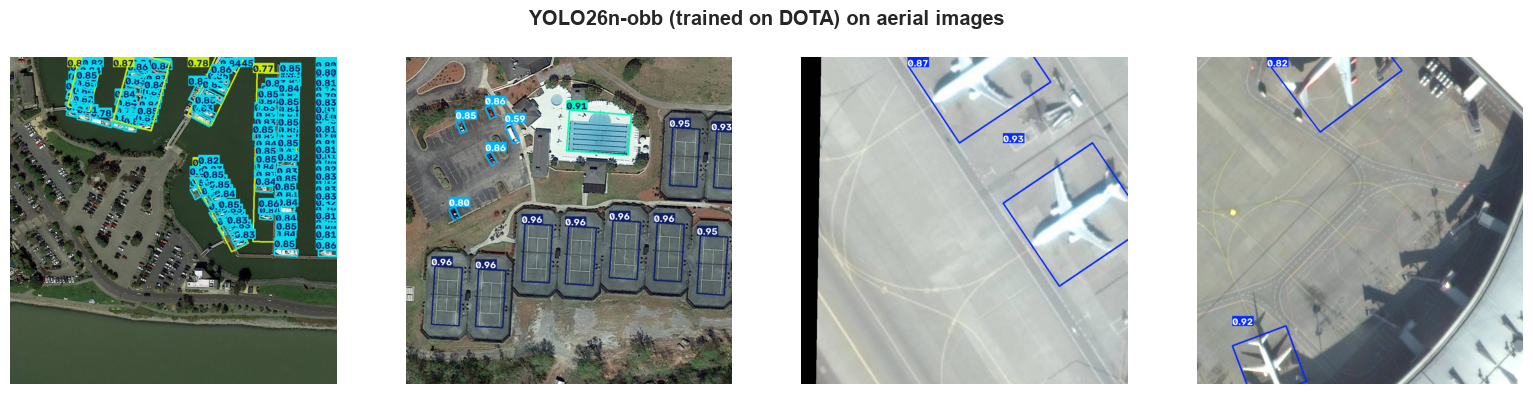

,ship,harbor,tennis court,small vehicle,swimming pool,plane
P0861__1024__0___1648,128,6,0,0,0,0
P1053__1024__0___90,0,0,9,5,1,0
P1142__1024__0___824,0,0,0,0,0,2
P1161__1024__3296___1648,0,0,0,0,0,2


In [4]:
dota8_yaml = yolo_dataset("dota8")
dota_model = YOLO(str(WEIGHTS / "yolo26n-obb.pt"))
NAMES = dota_model.names
imgs = sorted((YOLO_DATA / "dota8" / "images").rglob("*.jpg"))
res = dota_model.predict(imgs[:4], imgsz=1024, conf=0.3, device=DEVICE)
show_images([r.plot(labels=False)[..., ::-1] for r in res], ncols=4, size=4,
            suptitle="YOLO26n-obb (trained on DOTA) on aerial images")

counts = pd.DataFrame([pd.Series([NAMES[int(c)] for c in r.obb.cls]).value_counts() for r in res],
                      index=[p.stem for p in imgs[:4]]).fillna(0).astype(int)
counts

Each detection comes as `r.obb.xywhr` (centre, size, angle) or `r.obb.xyxyxyxy` (corners). Counting cars or ships per
image is one line: that's how analysts estimate the activity of a port or the occupancy of a car park.

In [5]:
r = res[0]
print("first 3 boxes as xywhr:\n", r.obb.xywhr[:3].cpu().numpy().round(1))
print("angles (degrees):", np.degrees(r.obb.xywhr[:8, 4].cpu().numpy()).round(0))
checkpoint("obb/inference", xp=50)

first 3 boxes as xywhr:
 [[      411.9         107       123.9       221.6         0.3]
 [        395        57.5        49.6        16.9         0.2]
 [      995.5       613.8        57.9        20.6           0]]
angles (degrees): [         15          14           1          26           2          28         -25           3]
✅ Checkpoint · obb/inference (+50 XP)
   ████████████░░░░░░░░░░░░ 50/100 XP


## 3. Build your own OBB detector 🏗️

Now the competition situation: you have a **small labelled dataset** (DOTA128: 128 aerial images) and must train an
OBB model. We start from **YOLO26n trained on COCO for regular detection** and transfer its backbone into an OBB
architecture: `YOLO("yolo26n-obb.yaml").load("yolo26n.pt")`. The new OBB head starts from scratch.

⚠️ **A trap in the official DOTA128 config**: it validates on the *training* images (`val: images/train`). Any score
would be measured on images the model has memorised! We build an honest split: 100 images to train, 28 to validate.

In [6]:
dota128_yaml = yolo_dataset("dota128")
d128 = YOLO_DATA / "dota128"
all_imgs = sorted((d128 / "images" / "train").glob("*.jpg"))
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(all_imgs))
(d128 / "split_train.txt").write_text("\n".join(str(all_imgs[i]) for i in perm[:100]))
(d128 / "split_val.txt").write_text("\n".join(str(all_imgs[i]) for i in perm[100:]))
cfg = YAML.load(dota128_yaml)
cfg.update(train=str(d128 / "split_train.txt"), val=str(d128 / "split_val.txt"))
honest_yaml = YOLO_DATA / "dota128_honest.yaml"
YAML.save(honest_yaml, cfg)
print(f"train: 100 images · val: 28 images → {honest_yaml.name}")

train: 100 images · val: 28 images → dota128_honest.yaml


In [7]:
t0 = time.time()
obb_model = YOLO("yolo26n-obb.yaml").load(str(WEIGHTS / "yolo26n.pt"))   # OBB architecture + COCO backbone
metrics = obb_model.train(data=str(honest_yaml), epochs=30, imgsz=640, batch=8, device=DEVICE, workers=NUM_WORKERS,
                          project=str(RUNS_DIR / "obb"), name="dota128_from_coco", exist_ok=True,
                          plots=False, deterministic=False, seed=SEED)
print(f"⏱️  {(time.time() - t0) / 60:.1f} min · val mAP50 = {metrics.box.map50:.3f} · mAP50-95 = {metrics.box.map:.3f}")

lb = Leaderboard("dota128_obb", metric="val_mAP50")
lb.add("YOLO26n-obb · COCO backbone · 100 images · 30 epochs", metrics.box.map50, mAP50_95=round(metrics.box.map, 3))

⏱️  11.0 min · val mAP50 = 0.277 · mAP50-95 = 0.162
📋 YOLO26n-obb · COCO backbone · 100 images · 30 epochs: val_mAP50 = 0.27728


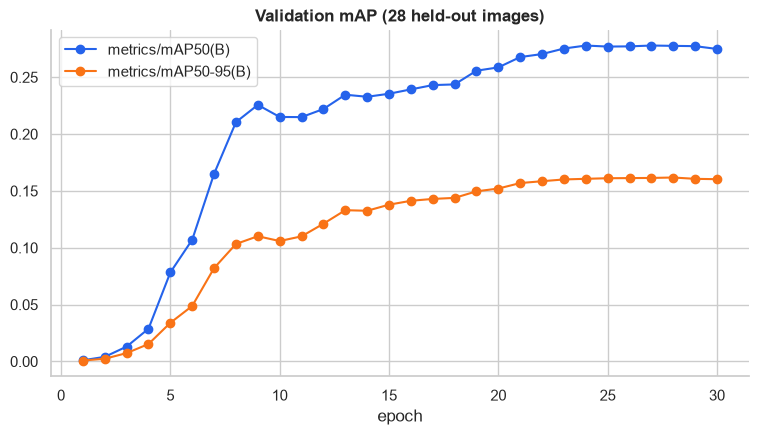

In [8]:
curves = pd.read_csv(Path(obb_model.trainer.save_dir) / "results.csv")
curves.columns = curves.columns.str.strip()
curves.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50-95(B)"], marker="o", title="Validation mAP (28 held-out images)")
plt.show()

## 4. How much does data matter? 📈

For comparison, we evaluate the official YOLO26n-obb, trained by Ultralytics on the **full DOTA dataset** (thousands of
image tiles, many epochs), on the same 28 validation images. Careful: DOTA128 was cut from DOTA's training set, so this
model has probably **seen** these images during its training: its score is an optimistic upper bound, not a fair
competitor.

In [9]:
ref = dota_model.val(data=str(honest_yaml), imgsz=640, batch=8, device=DEVICE, plots=False,
                     project=str(RUNS_DIR / "obb"), name="official_on_val", exist_ok=True)
lb.add("Official YOLO26n-obb (full DOTA, upper bound)", ref.box.map50, mAP50_95=round(ref.box.map, 3))
lb.show()

📋 Official YOLO26n-obb (full DOTA, upper bound): val_mAP50 = 0.96432  👑 new best!


,,model,val_mAP50,mAP50_95
rank,,,,
1,🥇,"Official YOLO26n-obb (full DOTA, upper bound)",0.96432,0.862
2,🥈,YOLO26n-obb · COCO backbone · 100 images · 30 ...,0.27728,0.162


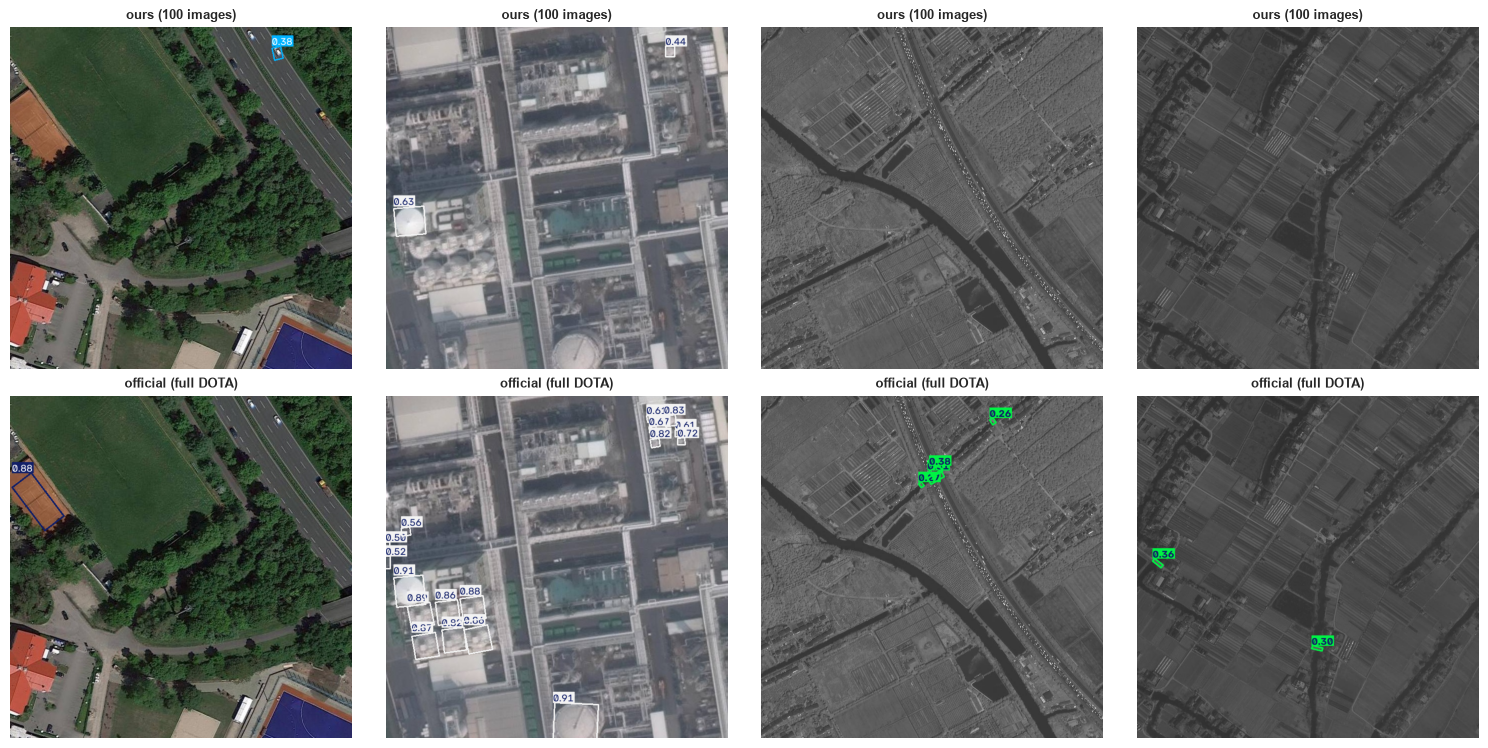

In [10]:
best = YOLO(str(Path(obb_model.trainer.save_dir) / "weights" / "best.pt"))
val_imgs = [all_imgs[i] for i in perm[100:104]]
mine = best.predict(val_imgs, imgsz=640, conf=0.25, device=DEVICE)
theirs = dota_model.predict(val_imgs, imgsz=640, conf=0.25, device=DEVICE)
show_images([r.plot(labels=False)[..., ::-1] for r in mine] + [r.plot(labels=False)[..., ::-1] for r in theirs],
            titles=["ours (100 images)"] * 4 + ["official (full DOTA)"] * 4, ncols=4, size=3.8)

**Lesson:** the architecture is identical; the difference is **data** (and training time). With 100 images and 30 epochs our
model starts to find the most distinctive objects (a storage tank here, a vehicle there) but misses most of them: a
mAP50 around 0.28 versus 0.96 for a model that has seen thousands of images (and, in this case, these very images). In
competitions, a large share of the leaderboard is won by better data: more images (pseudo-labelling, external data
when allowed), cleaner labels, smarter augmentation, and tiling large images.

## 🏁 Mission accomplished

### 🚀 Your turn (bonus XP)
1. Fine-tune the *official* `yolo26n-obb.pt` on the 100 training images instead of starting from COCO. (Then remember
   why its validation score cannot be trusted here!)
2. Train longer (100 epochs) or at `imgsz=1024`: small vehicles need pixels.
3. Count the small vehicles in each validation image and compare with the ground-truth labels.
4. DOTA images are huge: write a function that cuts a 2 048×2 048 image into overlapping 1 024 tiles, predicts each
   tile and merges the boxes (this is how aerial competitions are won).

In [11]:
checkpoint("obb/complete", xp=200)
badge("Eye in the Sky", "🛰️")
progress()

✅ Checkpoint · obb/complete (+200 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██████████████████░░░░░░ 250/300 XP
╔════════════════════════════════════╗
║ 🛰️  BADGE UNLOCKED: Eye in the Sky ║
╚════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 2
Badges: 🛰️ Eye in the Sky
